# Fig. S4: Additional Fabrication Robustness

This notebook loads saved results and plots focusing efficiency for optimized diffractive cascades with several element counts \(N\) against a baseline Fresnel zone plate.

The three panels show:

1. **Dilation** — systematic expansion of features
2. **Radius of curvature (ROC)** — rounded sidewalls from a finite etch radius
3. **Element tilt** — independent zero-mean Gaussian rotations of each element about its local \(x\) and \(y\) axes


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [2]:
import sys
from pathlib import Path

repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(repo_root))
from src.util import colors_list


In [3]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams.update({'font.size': 24})

In [4]:
fzp_color = (np.float64(0.4), np.float64(0.6509803921568628), np.float64(0.11764705882352941), np.float64(1.0))

# Dilation


In [5]:
dilation_path = repo_root / "paper_data"
dilation_results = np.load(dilation_path / "figS4a_dilation_robustness_results.npz", allow_pickle=True)

dilation_choices = dilation_results['choices']
dilation_fzp_mean_efficiencies = dilation_results['fzp_mean_efficiencies']
dilation_fzp_std_efficiencies = dilation_results['fzp_std_efficiencies']
dilation_opt_mean_efficiencies = dilation_results['opt_mean_efficiencies']
dilation_opt_std_efficiencies = dilation_results['opt_std_efficiencies']
dilation_strengths = dilation_results['morph_error_levels']
dilation_Nelem_arr = dilation_results['Nelem_arr']

# Radius of curvature and tilt

Each element receives independent zero-mean Gaussian rotations about its local \(x\) and \(y\) axes. The tilt-panel horizontal axis is the standard deviation of either angular component.


In [6]:
sw_path = repo_root / "paper_data"
sw_results = np.load(sw_path / "figS4b_sidewall_robustness_results.npz", allow_pickle=True)

sw_choices = sw_results['choices']
sw_fzp_mean_efficiencies = sw_results['fzp_mean_efficiencies']
sw_fzp_std_efficiencies = sw_results['fzp_std_efficiencies']
sw_opt_mean_efficiencies = sw_results['opt_mean_efficiencies']
sw_opt_std_efficiencies = sw_results['opt_std_efficiencies']
radii = sw_results['blur_radii']
sw_Nelem_arr = sw_results['Nelem_arr']

tilt_path = repo_root / "paper_data"
tilt_canonical = tilt_path / "figS4c_tilt_robustness_results.npz"
if tilt_canonical.exists():
    tilt_results_file = tilt_canonical
else:
    tilt_result_files = sorted(tilt_path.glob("figS4c_tilt_robustness_results_*.npz"))
    if not tilt_result_files:
        raise FileNotFoundError("Run paper/postprocess/tilt_robustness.py first")
    tilt_results_file = tilt_result_files[-1]

tilt_results = np.load(tilt_results_file, allow_pickle=True)
print(f"Loaded {tilt_results_file.name}")

tilt_choices = tilt_results['choices']
tilt_fzp_mean_efficiencies = tilt_results['fzp_mean_efficiencies']
tilt_fzp_std_efficiencies = tilt_results['fzp_std_efficiencies']
tilt_opt_mean_efficiencies = tilt_results['opt_mean_efficiencies']
tilt_opt_std_efficiencies = tilt_results['opt_std_efficiencies']
tilt_error_mrad = tilt_results['tilt_error_mrad']
tilt_Nelem_arr = tilt_results['Nelem_arr']

Loaded figS4c_tilt_robustness_results.npz


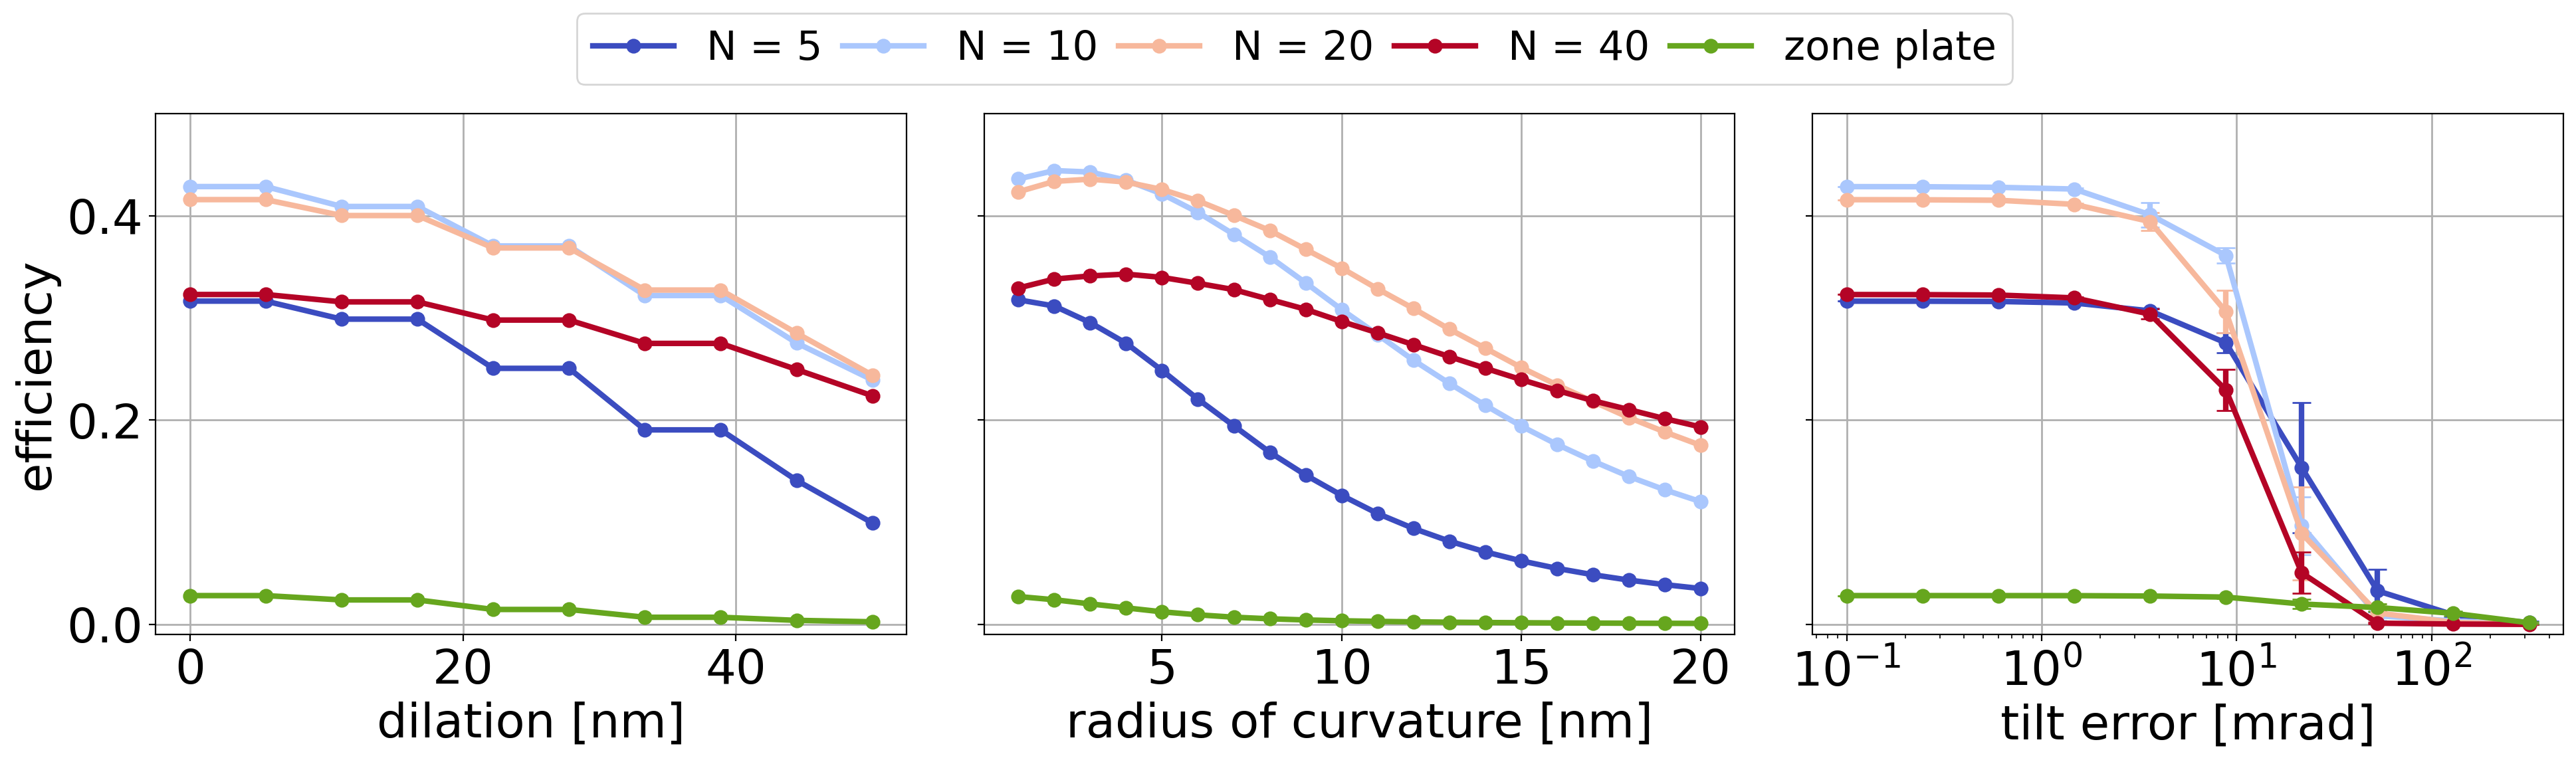

In [7]:
colors = colors_list(len(dilation_Nelem_arr))

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)

ax[0].set_xlabel("dilation [nm]", fontsize=26)

for i in range(len(dilation_Nelem_arr)):
    ax[0].plot(dilation_strengths*1e9, dilation_opt_mean_efficiencies[i], linewidth=3, marker='o', markersize=7, label=f'N = {dilation_Nelem_arr[i]}', color=colors[i])
    
ax[0].plot(dilation_strengths*1e9, dilation_fzp_mean_efficiencies[0], linewidth=3, marker='o', markersize=7, label='zone plate', color=fzp_color)

ax[1].set_xticks([0, 5, 10, 15, 20])
ax[1].set_xlabel("radius of curvature [nm]", fontsize=26)

for i in range(len(sw_Nelem_arr)):
    ax[1].plot(radii*2, sw_opt_mean_efficiencies[i], linewidth=3, marker='o', markersize=7, label=f'N = {sw_Nelem_arr[i]}', color=colors[i])
    
ax[1].plot(radii*2, sw_fzp_mean_efficiencies[0], linewidth=3, marker='o', markersize=7, label='zone plate', color=fzp_color)

ax[2].set_xscale('log')
ax[2].set_xlabel("tilt error [mrad]", fontsize=26)

for i in range(len(tilt_Nelem_arr)):
    ax[2].errorbar(
        tilt_error_mrad,
        tilt_opt_mean_efficiencies[i],
        yerr=tilt_opt_std_efficiencies[i],
        linewidth=3,
        fmt='-o',
        capsize=5,
        markersize=7,
        label=f'N = {tilt_Nelem_arr[i]}',
        color=colors[i],
    )

ax[2].errorbar(
    tilt_error_mrad,
    tilt_fzp_mean_efficiencies[0],
    yerr=tilt_fzp_std_efficiencies[0],
    linewidth=3,
    fmt='-o',
    capsize=5,
    markersize=7,
    label='zone plate',
    color=fzp_color,
)

for idx, axi in enumerate(ax):
    # Formatting each subplot
    axi.set_ylim(-0.01, 0.5)
    axi.tick_params(labelsize=26)
    axi.grid(True, linewidth=1)
    
    # Only show legend on the first or last plot to avoid clutter, 
    # or adjust as needed.
    if idx == 0:
        axi.set_ylabel("efficiency", fontsize=26)
        # axi.legend(fontsize=18)

handles, labels = ax[0].get_legend_handles_labels() 
fig.legend(handles, labels, loc='outside upper center', ncol=5, columnspacing=0.5, bbox_to_anchor=(0.5, 1.1), fontsize=22) 

fig.subplots_adjust(wspace=5, hspace=5)

plt.tight_layout()
plt.show()